# Лабораторная 4. Конкурсная часть с дополнительными данными

Maksim Kostromitin  
Group: J4132

Это дополнительный вариант части 3 задания: классификация кошек и собак с внешними фотографиями. В конкурсной части запрещены готовые предобученные веса. Первые сети обучены со случайными весами; поздние этапы продолжают обучение собственных моделей. Веса ImageNet здесь не используются.

В конкурсной части [основного ноутбука](Task_4_Maksim_Kostromitin_Group_J4132.ipynb) используются только данные курса; точность — 98,56%. Здесь проверяю, помогают ли дополнительные условия съёмки, позы и породы. Результат 99,04% относится к этому отдельному опыту.

Запуск — из папки `lab4`, зависимости перечислены в `requirements.txt`. По умолчанию тест оценивается по сохранённым прогнозам, а отдельное фото проходит весь ансамбль. `RUN_TEST = True` пересчитывает ответы по всем тестовым фотографиям; обучение включается отдельно.


In [1]:
import hashlib
import json
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image, ImageOps
from scipy.special import expit, logit
from sklearn.tree import DecisionTreeRegressor
from torch import nn
from torch.nn import functional as F

import contest
import hw4
import train_external as training
from contest import Attention, CourseConvNeXt, GeMResNet, HybridBlock, hybrid_conv

results, manifests = hw4.prepare()
RUN_TEST = False


## Данные и разбиение

COCO и Open Images содержат сцены с небольшими и частично закрытыми животными, для которых указаны рамки. Oxford и Stanford добавляют разные породы, PetFinder — фотографии животных из объявлений. Ссылки и сведения об авторах фотографий COCO/Open Images сохранены в списках данных. Из Oxford беру фотографии и метки пород; маски сегментации не используются.

Источники: [COCO](https://cocodataset.org/), [Open Images](https://storage.googleapis.com/openimages/web/index.html), [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), [Stanford Dogs](https://vision.stanford.edu/aditya86/ImageNetDogs/), [PetFinder для обучения](https://huggingface.co/datasets/multabench/core-img-cls-petfinder/tree/be8a8008e4ed5a3de7391b2b4f3a60b247d50cba) и [PetFinder для калибровки](https://automl-mm-bench.s3.amazonaws.com/petfinder_kaggle.zip?versionId=vIt1xaDcs9K81HHycW9shuAVDrkMvT0C).

В таблице показано число отобранных фотографий. Признак `contest` в списке данных курса задаёт 19 991 фото для обучения, 2 487 для проверки и 2 500 для итогового теста. Нейросети используют обучающие части курса и дополнительных наборов. Ещё 3 832 фотографии PetFinder нужны для калибровки вероятностей; по номерам животных они не пересекаются с 14 516 обучающими фотографиями PetFinder.


In [2]:
files = pd.read_csv(manifests / "external_files.csv")
dataset_order = ["coco", "open-images", "oxford", "stanford", "petfinder", "petfinder-cal"]
counts = files.groupby("dataset").size().reindex(dataset_order)
display(counts.rename(index={
    "coco": "COCO", "open-images": "Open Images", "oxford": "Oxford", "stanford": "Stanford",
    "petfinder": "PetFinder: обучение", "petfinder-cal": "PetFinder: калибровка",
}).rename_axis("Набор данных").rename("Фотографий").to_frame())

course = pd.read_csv(manifests / "course_all.csv")
display(course.loc[course.contest].groupby("split").size()
        .reindex(["train", "val", "test"])
        .rename(index={"train": "Обучение", "val": "Проверка", "test": "Тест"})
        .rename_axis("Выборка").rename("Фотографий курса").to_frame())

pet_train = pd.read_csv(manifests / "rescue_train.csv")
pet_cal = pd.read_csv(manifests / "external_cal_manifest.csv")
train_animals = set(pet_train.name.map(lambda name: Path(name).stem.split("-")[0]))
cal_animals = set(pet_cal.source)
print("Общих животных в обучающей и калибровочной частях PetFinder:", len(train_animals & cal_animals))


Общих животных в обучающей и калибровочной частях PetFinder: 0


,Фотографий
Набор данных,
COCO,4596
Open Images,2860
Oxford,3642
Stanford,11870
PetFinder: обучение,14516
PetFinder: калибровка,3832


,Фотографий курса
Выборка,
Обучение,19991
Проверка,2487
Тест,2500


## Как устроен ансамбль

Сначала дополняю курсовой прогноз моделями на COCO. Модели поиска животного выделяют сложные кадры. Для них отдельные сети сравнивают целое изображение и вырез с животным. Получается промежуточный ансамбль, который в коде обозначен `prior`.

Дальше добавляются две модели с вниманием — на данных курса и на дополнительных фотографиях, модель с определением породы, модель с устойчивым обучением, модель с частотными преобразованиями и модель на признаках двух сетей. Калибратор использует их вероятности, промежуточный ансамбль, курсовой прогноз после обучения с перекрытиями и признаки изображения. В конце ответ уточняют свёрточная сеть с вниманием и уже использованная модель на признаках двух сетей.

| Имя этапа в коде | Назначение и начальные веса |
|---|---|
| `coco_full` | Остаточная свёрточная сеть на целых кадрах курса и COCO; случайные веса |
| `coco_focus` | Сеть с поканальными свёртками и дополнительными вырезами COCO; случайные веса |
| `joint_location` | Совместная классификация и поиск рамки животного; случайные веса |
| `detector` | Небольшая сеть поиска животного для выбора вырезов; случайные веса |
| `pose_resnet`, `pose_mobile` | Две сети для сложных поз, перекрытий и вырезов COCO/Open Images; случайные веса |
| `new_specialist` | Дообучение сети на целых кадрах на трудных примерах и искусственных перекрытиях |
| `context` | Модель с вниманием: соединяет локальные и общие признаки; основа — сеть на целых кадрах, добавлены Oxford/Stanford |
| `joint` | Модель с дополнительным определением породы; основа — модель с вниманием, используются все пять внешних обучающих наборов |
| `stable` | Модель с устойчивым обучением: учитывает небольшие возмущения весов; основа — модель с вниманием, добавлен PetFinder |
| `spectrum` | Модель с частотными преобразованиями: смешивает амплитуды спектра Фурье и учитывает возраст, размер и шерсть; основа — сеть на целых кадрах, добавлен PetFinder |
| `hybrid` | Свёрточная сеть с вниманием; основа — собственная курсовая версия, затем Oxford/Stanford и перенос признаков от сети на целых кадрах |
| `native` | Модель на признаках двух замороженных сетей: сети на целых кадрах и собственного курсового ConvNeXt; блок внимания обучается на курсе и PetFinder |

Это 13 внешних этапов. Для последних двух сохранены исходные курсовые модели `course_hybrid` и `course_convnext`. Их мягкие метки учитывают ответы ранее обученных курсовых сетей; свёрточная сеть с вниманием также приближает их признаки.


### Параметры обучения

AdamW подбирает масштаб обновления каждого веса по накопленным градиентам и отдельно уменьшает веса для регуляризации. Шаг обучения уменьшается по косинусному расписанию; часть этапов начинается с плавного увеличения шага. В таблице указаны исходные коэффициенты шага; множители относятся к новым выходным слоям. Вместе с размером изображения меняется число снимков в одной порции данных. Начальное число фиксирует случайные действия для повторения опыта.

Специалист по сложным кадрам накапливает градиенты четырёх порций по 16 снимков перед обновлением весов. У модели на признаках двух сетей изображения 448×448 заранее преобразованы в векторы признаков, поэтому порция из 96 примеров относится только к обучаемой части.


In [3]:
stages = pd.DataFrame([
    ("coco_full", 100, "112 → 160 → 224 → 256", "96", "0.00130", 0.025, 62041),
    ("coco_focus", 108, "112 → 160 → 224 → 256", "96", "0.00165", 0.025, 62177),
    ("joint_location", 108, "112 → 160 → 224 → 256", "96", "0.00130", 0.025, 72041),
    ("detector", 72, "128 → 192 → 224", "96", "0.00170", 0.025, 72077),
    ("pose_resnet", 94, "112 → 160 → 224 → 256", "96", "0.00140", 0.028, 73141),
    ("pose_mobile", 88, "112 → 160 → 224 → 256", "96", "0.00165", 0.028, 73189),
    ("new_specialist", 10, "288", "16 × 4", "0.00010", 0.020, 82177),
    ("context", 22, "192 → 256 → 320", "28 → 20", "0.00019; голова ×3.8", 0.040, 86018),
    ("joint", 38, "224 → 256 → 288", "30 → 28", "0.00020; голова ×4", 0.035, 79009),
    ("stable", 20, "224 → 256 → 288", "24", "0.00009; голова ×1.2", 0.035, 90042),
    ("spectrum", 32, "224 → 288", "24", "0.00030; группы ×1/8/5", 0.025, 78114),
    ("hybrid", 32, "176 → 224 → 288", "64 → 40 → 28", "0.00024", 0.045, 57230),
    ("native", 24, "448", "96", "0.00070", 0.050, 7237),
    ("course_hybrid", 64, "128 → 176 → 224 → 288", "80 → 64 → 40 → 28", "0.00090", 0.045, 57229),
    ("course_convnext", 60, "112 → 160 → 192 → 224", "80 → 56 → 40", "0.00120", 0.035, 82231),
], columns=["Этап", "Эпох", "Сторона входа", "Размер порции", "Шаг обучения", "Регуляризация весов", "Начальное число"])
display(stages.set_index("Этап"))


,Эпох,Сторона входа,Размер порции,Шаг обучения,Регуляризация весов,Начальное число
Этап,,,,,,
coco_full,100,112 → 160 → 224 → 256,96,0.00130,0.025,62041
coco_focus,108,112 → 160 → 224 → 256,96,0.00165,0.025,62177
joint_location,108,112 → 160 → 224 → 256,96,0.00130,0.025,72041
detector,72,128 → 192 → 224,96,0.00170,0.025,72077
pose_resnet,94,112 → 160 → 224 → 256,96,0.00140,0.028,73141
pose_mobile,88,112 → 160 → 224 → 256,96,0.00165,0.028,73189
new_specialist,10,288,16 × 4,0.00010,0.020,82177
context,22,192 → 256 → 320,28 → 20,0.00019; голова ×3.8,0.040,86018
joint,38,224 → 256 → 288,30 → 28,0.00020; голова ×4,0.035,79009


### Модель с вниманием

Класс `Context` получает две карты признаков остаточной сети GeM-ResNet: на 160 и 320 каналов. Каждая область карты превращается в вектор из 128 чисел. Два блока внимания с четырьмя параллельными головами связывают локальные детали и целый кадр. Отдельный общий вектор даёт логит — ответ до преобразования в вероятность собаки. Ещё одна проекция нужна для сближения признаков изображений одного класса при обучении. Общие свёрточные блоки импортирую из `contest.py`.


In [4]:
class Context(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = GeMResNet()
        self.local = nn.Conv2d(160, 128, 1)
        self.global_tokens = nn.Conv2d(320, 128, 1)
        self.pos = nn.Conv2d(128, 128, 3, padding=1, groups=128)
        self.cls = nn.Parameter(torch.randn(1, 1, 128) * 0.02)
        self.blocks = nn.Sequential(Attention(128), Attention(128), nn.LayerNorm(128))
        self.classify = nn.Linear(128, 1)
        self.project = nn.Linear(128, 64)

    def features(self, x):
        local = self.base.stages[:13](self.base.stem(x))
        global_map = self.base.stages[13:](local)
        small, big = self.global_tokens(global_map), self.local(local)

        def tokens(z):
            return (z + self.pos(z)).flatten(2).transpose(1, 2)

        stack = torch.cat([
            self.cls.expand(len(x), -1, -1), tokens(big), tokens(small)
        ], dim=1)
        return self.blocks(stack)[:, 0]

    def forward(self, x, embedding=False):
        summary = self.features(x)
        logits = self.classify(summary).flatten()
        if embedding:
            return logits, F.normalize(self.project(summary).float(), dim=1)
        return logits


### Свёртки и внимание

Класс `Hybrid` сочетает остаточные свёрточные блоки и внимание. Свёртки уменьшают изображение в 16 раз, число каналов меняется так: 32 → 48 → 96 → 192. Четыре блока внимания обрабатывают векторы разных областей. Общий вектор, средний вектор областей и максимум свёрточной карты объединяются в 576 признаков. Выходные слои дают логит и, при обучении, 560 признаков для сравнения с ранее обученной сетью-учителем.


In [5]:
class Hybrid(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            hybrid_conv(3, 32, 3, 2), hybrid_conv(32, 48, 3, 2), HybridBlock(48),
            hybrid_conv(48, 96, 3, 2), HybridBlock(96), HybridBlock(96),
            hybrid_conv(96, 192, 3, 2), HybridBlock(192), HybridBlock(192), HybridBlock(192),
        )
        self.pos = nn.Conv2d(192, 192, 3, padding=1, groups=192)
        self.cls = nn.Parameter(torch.randn(1, 1, 192) * 0.02)
        self.global_layers = nn.Sequential(
            *[Attention(192) for _ in range(4)], nn.LayerNorm(192)
        )
        self.representation = nn.Sequential(nn.LayerNorm(576), nn.Linear(576, 384), nn.GELU())
        self.species = nn.Linear(384, 1)
        self.features = nn.Linear(384, 560)

    def forward(self, x, teacher=False):
        local = self.stem(x)
        tokens = (local + self.pos(local)).flatten(2).transpose(1, 2)
        z = self.global_layers(torch.cat([self.cls.expand(len(x), -1, -1), tokens], 1))
        shared = self.representation(
            torch.cat([z[:, 0], z[:, 1:].mean(1), local.amax((2, 3))], 1)
        )
        score = self.species(shared).flatten()
        return (score, self.features(shared).float()) if teacher else score


### Модель на признаках двух сетей

Класс `Native` получает изображение 448×448. Замороженные GeM-ResNet и курсовой ConvNeXt дают карты на 480 и 512 признаков. Метод главных компонент сжимает каждую до 64: получается сетка 12×12, где каждой области соответствует вектор из 128 чисел. Пять обучаемых запросов механизма внимания выбирают полезные области. Итоговый логит складывает общий ответ и объединённые ответы этих областей. Обе исходные сети и преобразования признаков входят в сохранённые веса.


In [6]:
class Native(nn.Module):
    def __init__(self):
        super().__init__()
        self.res = GeMResNet()
        self.conv = CourseConvNeXt()
        self.register_buffer("offset", torch.zeros(2, 512))
        self.register_buffer("components", torch.zeros(2, 512, 64))
        self.register_buffer("widths", torch.tensor([480, 512]))
        self.local = nn.Sequential(nn.LayerNorm(128), nn.Linear(128, 160), nn.GELU(), nn.Linear(160, 128))
        self.queries = nn.Parameter(torch.randn(5, 128) * 0.035)
        self.attention = nn.MultiheadAttention(128, 4, batch_first=True)
        self.site = nn.Linear(128, 1)
        self.head = nn.Sequential(nn.LayerNorm(768), nn.Linear(768, 192), nn.GELU(), nn.Dropout(0.22), nn.Linear(192, 1))

    def maps(self, x):
        r = self.res.stages[:13](self.res.stem(x))
        r2 = self.res.stages[13:](r)
        c = self.conv.layers[:-4](x)
        c2 = self.conv.layers[-4:](c)

        def dense(a, b):
            a = F.adaptive_avg_pool2d(a, (12, 12))
            b = F.adaptive_avg_pool2d(b, (12, 12))
            return torch.cat([a, b], 1).flatten(2).transpose(1, 2).float()

        return dense(r, r2), dense(c, c2)

    def encode(self, x):
        return torch.cat([
            (feat - self.offset[k, :feat.shape[-1]]) @ self.components[k, :feat.shape[-1]]
            for k, feat in enumerate(self.maps(x))
        ], dim=-1)

    def classify(self, features):
        z = self.local(features.float())
        pooled, _ = self.attention(self.queries.expand(len(z), -1, -1), z, z, need_weights=False)
        summary = torch.cat([pooled.flatten(1), z.mean(1)], 1)
        return (self.head(summary).flatten() + self.site(z).float().logsumexp(1).flatten()
                - math.log(z.shape[1]))

    def forward(self, x):
        return self.classify(self.encode(x))


### Шаг обучения свёрточной сети с вниманием

В каждую порцию данных добавляются 8 фотографий Oxford и 4 Stanford. Для снимков курса мягкая цель равна $t=0{,}88y+0{,}12p$, где $y$ — метка, а $p$ — средняя вероятность трёх ранее обученных курсовых сетей. Затем цель сглаживается: $0{,}994t+0{,}003$. Функция потерь соединяет двоичную перекрёстную энтропию и косинусное расстояние до признаков сети, обученной на целых кадрах курса и COCO:

$$L=L_{\text{классы}}+\left(0{,}70-0{,}40\frac{e}{31}\right)L_{\text{признаки}}.$$

Здесь $e$ — номер эпохи, начиная с нуля. После обратного распространения градиент ограничивается нормой 3, выполняется шаг AdamW и обновляется сглаженная копия весов с коэффициентом 0,988.


In [7]:
def apply_update(loss, model, optimizer, ema=None, decay=None, clip=3.0):
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
    optimizer.step()
    if ema is not None:
        contest.average(ema, model, decay)


def hybrid_epoch(model, ema, opt, reference, epoch, edge, rng):
    phase = epoch / 31
    batch = {176: 64, 224: 40, 288: 28}[edge]
    count = batch - 12
    order = rng.permutation(len(training.course_y))
    model.train()
    for start in range(0, len(order) - count + 1, count):
        ix = order[start:start + count]
        x = training.train_pixels(training.train_frames, ix, edge)
        target = 0.88 * training.course_y[ix] + 0.12 * training.teacher_p[ix]
        x, y = training.oxford_stanford(x, target, edge, rng, 8, 4)
        x = contest.augment(x, True)
        with training.amp_train():
            logits, embedding = model(x, teacher=True)
            species = F.binary_cross_entropy_with_logits(logits.float(), 0.994 * y + 0.003)
            distance = 1 - F.cosine_similarity(embedding[:count], reference[ix]).mean()
            loss = species + (0.70 - 0.40 * phase) * distance
        apply_update(loss, model, opt, ema, 0.988)


### Повторное обучение

Для запуска нужна видеокарта NVIDIA с поддержкой CUDA и формата вычислений `bfloat16`. Имена этапов берутся из таблицы выше. По умолчанию выбраны свёрточная сеть с вниманием и модель на признаках двух сетей, но обучение выключено. Классы и шаг обучения из ячеек выше подключаются к `train_external.py`.

Новые запуски сохраняют отдельные веса. Поздние этапы читают архивные исходные модели, а модель на признаках двух сетей — ещё и сохранённые преобразования признаков. Для замены исходных моделей и пересборки всего ансамбля нужно заново выбрать веса и настроить калибровку.


In [8]:
RETRAIN_EXTERNAL = False
RETRAIN_PARENTS = False
EXTERNAL_STAGES = ["hybrid", "native"]
PARENT_STAGES = ["course_hybrid", "course_convnext"]

if RETRAIN_EXTERNAL or RETRAIN_PARENTS:
    training.Context, training.Hybrid, training.Native = Context, Hybrid, Native
    training.apply_update = apply_update
    training.hybrid_epoch = hybrid_epoch
    training.main([
        "--stages", *(EXTERNAL_STAGES if RETRAIN_EXTERNAL else []),
        "--parents", *(PARENT_STAGES if RETRAIN_PARENTS else []),
    ])


### Кривые обучения

Слева — сохранённые потери свёрточной сети с вниманием на обучающей выборке. Справа — потери при добавлении каждой модели к промежуточному ансамблю на части проверочной выборки для подбора параметров. Вес добавления у этапов различается, поэтому эти линии показывают ход обучения, а не сравнивают одиночные сети. Для модели с определением породы, модели с устойчивым обучением и модели на признаках двух сетей обучающие потери в журнале не сохранены.


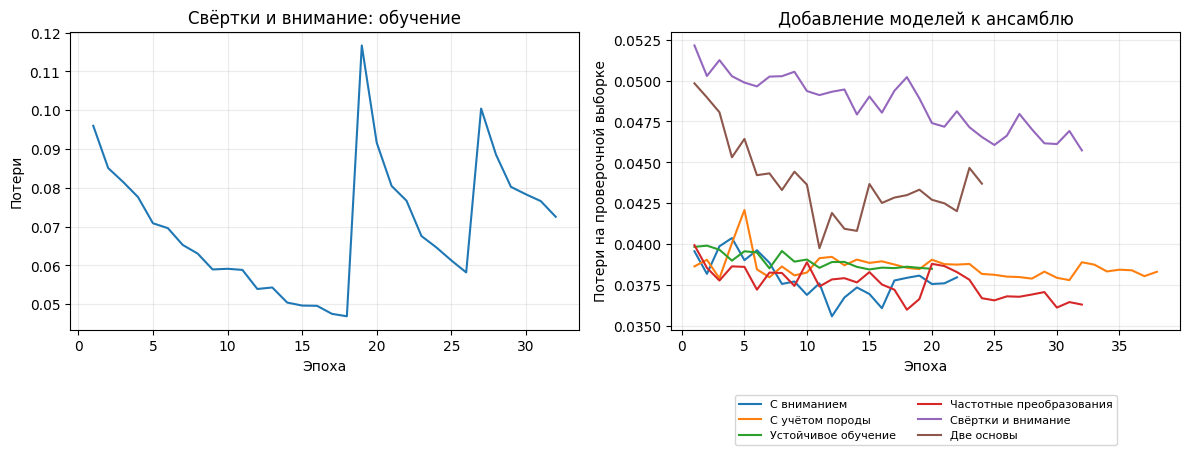

In [9]:
model_labels = {
    "context": "С вниманием", "joint": "С учётом породы", "stable": "Устойчивое обучение",
    "spectrum": "Частотные преобразования", "hybrid": "Свёртки и внимание", "native": "Две основы",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
hybrid_history = pd.read_csv(results / "external_hybrid_history.csv")
axes[0].plot(hybrid_history.epoch, hybrid_history.train_loss)
axes[0].set(title="Свёртки и внимание: обучение", xlabel="Эпоха", ylabel="Потери")
for name in ["context", "joint", "stable", "spectrum", "hybrid", "native"]:
    history = pd.read_csv(results / f"external_{name}_history.csv")
    loss_column = "loss" if name == "stable" else "dev_loss"
    axes[1].plot(history.epoch, history[loss_column], label=model_labels[name])
axes[1].set(title="Добавление моделей к ансамблю", xlabel="Эпоха", ylabel="Потери на проверочной выборке")
axes[1].legend(ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Промежуточный ансамбль

В коде `initial` — курсовой прогноз до этапа обучения с искусственными перекрытиями, `course` — после него. Итоговые 98,56% основного ноутбука дополнительно используют курсовую модель с вниманием, поэтому это другой прогноз.

Функция `previous_coco` усредняет логиты раннего курсового ансамбля и двух моделей на COCO с равными весами. Затем `route_evidence` сравнивает ответы на целый кадр и вырез с животным. По сохранённому порогу сложные кадры отправляются специалистам. Для них используются две модели сложных поз, специалист по вырезам и курсовой прогноз после обучения с перекрытиями. Вырезы и веса смешивания выбраны на проверочной выборке; остальные снимки сохраняют ответ ансамбля с COCO.


In [10]:
def predecessor(paths, folder):
    previous = folder / "previous"
    baseline = previous / "baseline"
    initial, course_probability = contest.course_prior(paths, baseline, previous)
    coco = contest.previous_coco(paths, initial, baseline)
    recipe = contest.load_json(baseline / "specialist/selection.json")
    rows = contest.route_evidence(
        Path("."), paths, baseline / "current", baseline / "localize", coco, contest.DEVICE
    )
    method = contest.load_json(baseline / "localize/selection.json")["alert"]["method"]
    flags = contest.flag_scores(rows)[method] >= recipe["cutoff"]
    rows["flagged"] = flags
    if not flags.any():
        return coco, course_probability
    prior = contest.predict_specialist(
        Path("."), rows, flags, baseline / "specialist", recipe, contest.DEVICE
    )
    prior = contest.specialist_vote(
        rows, flags, prior, course_probability, baseline, previous,
        contest.load_json(previous / "selection.json"),
    )
    return prior, course_probability


Сохранённые результаты показывают, как менялось решение при добавлении этапов. Эти проверки участвовали в выборе моделей и правил. Таблица описывает ход работы на проверочной выборке; итоговый тест приведён отдельно.


In [11]:
weights_folder = hw4.open_models("winners")
baseline_folder = weights_folder / "previous/baseline"
history_steps = []
for title, file in [
    ("COCO-ансамбль", baseline_folder / "current/selection.json"),
    ("Локализация", baseline_folder / "localize/selection.json"),
    ("Специалист по вырезам", baseline_folder / "specialist/selection.json"),
]:
    selection = json.loads(file.read_text())
    history_steps.append((title, selection["correct"], selection["n"]))
selection = json.loads((weights_folder / "previous/selection.json").read_text())
history_steps.append(("Предшествующий внешний ансамбль", selection["external"]["correct"], selection["n"]))
for title, file in [("Калибровка", "external_calibration.json"), ("Уточнение двумя моделями", "external_selection.json")]:
    score = json.loads((results / file).read_text())["validation"]["all"]["after"]
    history_steps.append((title, score["correct"], score["n"]))
progress = pd.DataFrame(history_steps, columns=["Этап", "Верно", "Всего"]).set_index("Этап")
progress["Точность, %"] = (100 * progress["Верно"] / progress["Всего"]).round(2)
display(progress)


,Верно,Всего,"Точность, %"
Этап,,,
COCO-ансамбль,2460,2487,98.91
Локализация,2464,2487,99.08
Специалист по вырезам,2467,2487,99.20
Предшествующий внешний ансамбль,2470,2487,99.32
Калибровка,2471,2487,99.36
Уточнение двумя моделями,2473,2487,99.44


### Прогнозы отдельных моделей

Все новые модели, кроме модели на признаках двух сетей, усредняют логиты исходного кадра и его горизонтального отражения. Размер изображения берётся из сохранённых весов. Модель на признаках двух сетей использует кадр 448×448 без отражения.

Функция `model_probability` загружает нужную сеть и возвращает вероятность собаки. Модель с вниманием, свёрточная сеть с вниманием и модель на признаках двух сетей определены выше. Модель с определением породы и модель с частотными преобразованиями импортируются из `contest.py`.


In [12]:
def context_network():
    model = Context()
    model.base.head = nn.Identity()
    return model


NETWORKS = {
    "course_context": context_network,
    "external_context": context_network,
    "external_stable": context_network,
    "external_joint": contest.Taxonomy,
    "external_spectrum": contest.Spectrum,
    "external_native": Native,
    "external_hybrid": Hybrid,
}


def model_probability(name, lock, folder, paths, frames):
    file = folder / (name + ".pt")
    if hw4.checksum(file) != lock["hashes"][name]:
        raise ValueError(f"Не совпали веса {name}")
    state = torch.load(file, map_location="cpu", weights_only=True)
    model = NETWORKS[name]().to(contest.DEVICE, memory_format=torch.channels_last)
    model.load_state_dict(state["weights"])
    if name == "external_native":
        return contest.native_infer(model, paths)
    return contest.predict_component(model, frames, state["edge"])


## Калибровка на PetFinder

Калибратор получает восемь вероятностей в таком порядке: промежуточный ансамбль, курсовая модель с вниманием, внешняя модель с вниманием, модель с определением породы, модель с устойчивым обучением, модель с частотными преобразованиями, модель на признаках двух сетей и курсовой ансамбль после обучения с перекрытиями.

К логитам добавляются отклонения от промежуточного ансамбля, их модули, разброс и доля несогласных ответов. Ещё 48 признаков описывают пропорции, цвет и текстуру фотографии.

Обучаются 75 деревьев глубины 2. Каждое приближает ньютоновскую поправку $(y-p)/(p(1-p))$; значения листьев пересчитываются с регуляризацией и шагом 0,075. В `calibration.npz` сохранены ответы выбранных сетей на 3 832 отдельных фотографиях PetFinder. Метки итогового теста курса для этого не используются.


In [13]:
def features(p, image):
    z = np.clip(logit(p.clip(1e-5, 1 - 1e-5)), -8, 8)
    delta = z[:, 1:] - z[:, :1]
    return np.column_stack([
        z, delta, abs(delta), z.std(1),
        np.mean(z[:, 1:] * z[:, :1] < 0, axis=1), image,
    ])


def fit_tree(x, y, probability, index):
    hessian = (probability * (1 - probability)).clip(0.015)
    residual = np.clip((y - probability) / hessian, -6, 6)
    tree = DecisionTreeRegressor(
        max_depth=2, min_samples_leaf=max(45, len(x) // 56),
        max_features=0.8, random_state=5540 + index,
    )
    tree.fit(x, residual, sample_weight=hessian)
    leaves = tree.apply(x)
    for leaf in np.unique(leaves):
        mask = leaves == leaf
        step = (y[mask] - probability[mask]).sum() / (hessian[mask].sum() + 4)
        tree.tree_.value[leaf, 0, 0] = 0.075 * np.clip(step, -1.7, 1.7)
    return tree


with np.load(results / "calibration.npz") as batch:
    calibration_inputs, calibration_labels = batch["inputs"], batch["y"]
    calibration_features = features(calibration_inputs, batch["appearance"])
base_logits = logit(calibration_inputs[:, 0].clip(1e-5, 1 - 1e-5))
correction = np.zeros(len(calibration_labels))
trees = []
for i in range(75):
    tree = fit_tree(calibration_features, calibration_labels, expit(base_logits + correction), i)
    correction += tree.predict(calibration_features)
    trees.append(tree)
print(f"Калибровка: {len(calibration_labels)} фото, {calibration_features.shape[1]} признака, {len(trees)} деревьев")


Калибровка: 3832 фото, 72 признака, 75 деревьев


### Смешивание с поправкой

Суммарная поправка к логиту ограничена интервалом $[-3;3]$. Исправленный ответ смешивается с промежуточным ансамблем в пространстве логитов с весом **0,30**. Для опубликованного прогноза используются сохранённые 75 деревьев; деревья, обученные выше, проверяются отдельно.

Обозначу исходную вероятность через $p_0$, поправку — через $\Delta$, перевод вероятности в логит — через $L$, обратное преобразование — через $\sigma$:

$$p_1=\sigma\left(L(p_0)+\Delta\right),\qquad p_2=\sigma\left(0{,}70L(p_0)+0{,}30L(p_1)\right).$$

В коде итог после калибровки обозначен `anchor`.


In [14]:
route_rule = json.loads((results / "external_calibration.json").read_text())
final_rule = json.loads((results / "external_selection.json").read_text())


def frozen_tree_delta(x, forest):
    correction = np.zeros(len(x))
    for tree in forest:
        node = np.zeros(len(x), dtype=int)
        for _ in range(2):
            left, right = np.asarray(tree["left"])[node], np.asarray(tree["right"])[node]
            column = np.asarray(tree["var"])[node].clip(0)
            go_left = x[np.arange(len(x)), column] <= np.asarray(tree["at"])[node]
            node = np.where(left < 0, node, np.where(go_left, left, right))
        correction += np.asarray(tree["value"])[node]
    return correction


def calibrated_probability(inputs, correction):
    prior = inputs[:, 0]
    adjusted = expit(logit(prior.clip(1e-5, 1 - 1e-5)) + correction.clip(-3, 3))
    weight = route_rule["weight"]
    return expit((1 - weight) * logit(prior.clip(1e-6, 1 - 1e-6))
                 + weight * logit(adjusted.clip(1e-6, 1 - 1e-6)))


### Последнее уточнение ответа

Свёрточная сеть с вниманием и модель на признаках двух сетей могут изменить откалиброванный ответ, когда обе уверены в противоположном классе: обе вероятности не ниже 0,8 для собаки или не выше 0,2 для кошки. Уверенность текущего ответа при этом не должна превышать 0,8.

Тогда итоговая вероятность равна $0{,}2p_2+0{,}8(p_3+p_4)/2$, где $p_3$ и $p_4$ — ответы этих двух моделей. В остальных случаях сохраняется $p_2$. Порог отнесения к классу во всех этапах — 0,5.


In [15]:
def final_probability(anchor, native, hybrid):
    group = np.column_stack([native, hybrid])
    alternative = group.mean(axis=1)
    confidence = final_rule["confidence"]
    sure = (group.min(axis=1) >= confidence) | (group.max(axis=1) <= 1 - confidence)
    opposed = (alternative >= 0.5) != (anchor >= 0.5)
    eligible = np.maximum(anchor, 1 - anchor) <= final_rule["anchor_limit"]
    return np.where(sure & opposed & eligible, 0.2 * anchor + 0.8 * alternative, anchor)


def accuracy(labels, probabilities):
    correct = (np.asarray(probabilities) >= 0.5) == np.asarray(labels)
    return pd.Series({
        "Верно": int(correct.sum()), "Всего": len(correct),
        "Точность, %": round(100 * correct.mean(), 2),
    })


## Подбор параметров и проверка

На последних этапах 2 487 проверочных фотографий курса делятся по контрольной сумме пути: 1 941 для подбора эпох и параметров, 546 для дополнительной проверки. Нейросети на этих снимках не обучаются. Однако ранние этапы уже подбирались по всей проверочной выборке, поэтому её вторая часть не является полностью независимым тестом.

Ниже сравниваются промежуточный ансамбль, заново обученный калибратор, сохранённый калибратор и финальное правило. Для всех строк взяты одни и те же фотографии. Калибратор уже обучен на всех 3 832 отведённых для него снимках PetFinder. Это оценка окончательного ансамбля; она не заменяет результаты промежуточных проверок при подборе параметров.


In [16]:
val = pd.read_csv(results / "validation.csv")
with np.load(results / "validation_features.npz") as batch:
    order = pd.Index(batch["paths"]).get_indexer(val.path)
    if (order < 0).any():
        raise ValueError("Не найдены признаки проверочной выборки")
    val_inputs = batch["inputs"][order]
    val_features = features(val_inputs, batch["appearance"][order])

refitted_anchor = calibrated_probability(val_inputs, sum(tree.predict(val_features) for tree in trees))
anchor = calibrated_probability(val_inputs, frozen_tree_delta(val_features, route_rule["trees"]))
val_probability = final_probability(anchor, val.external_native, val.external_hybrid)
is_dev = val.path.map(lambda p: int.from_bytes(
    hashlib.sha256(("hw4-subclass-v1/" + p).encode()).digest()[:4], "big"
) % 4 != 0).to_numpy()
validation_scores = {}
for split, keep in {"dev": is_dev, "check": ~is_dev, "all": np.ones(len(val), bool)}.items():
    for name, p in {
        "Предшествующий ансамбль": val_inputs[:, 0],
        "Калибратор из этой ячейки": refitted_anchor,
        "Сохранённый калибратор": anchor,
        "Финальный ансамбль": val_probability,
    }.items():
        validation_scores[(split, name)] = accuracy(val.label.to_numpy()[keep], p[keep])
display(pd.DataFrame(validation_scores).T
        .rename(index={"dev": "Подбор параметров", "check": "Дополнительная проверка", "all": "Вся проверочная выборка"}, level=0)
        .rename_axis(["Выборка", "Модель"]))


Верно   Всего  Точность, %
Выборка                 Модель                                                
Подбор параметров       Предшествующий ансамбль    1927.0  1941.0        99.28
                        Калибратор из этой ячейки  1928.0  1941.0        99.33
                        Сохранённый калибратор     1928.0  1941.0        99.33
                        Финальный ансамбль         1930.0  1941.0        99.43
Дополнительная проверка Предшествующий ансамбль     543.0   546.0        99.45
                        Калибратор из этой ячейки   543.0   546.0        99.45
                        Сохранённый калибратор      543.0   546.0        99.45
                        Финальный ансамбль          543.0   546.0        99.45
Вся проверочная выборка Предшествующий ансамбль    2470.0  2487.0        99.32
                        Калибратор из этой ячейки  2471.0  2487.0        99.36
                        Сохранённый калибратор     2471.0  2487.0        99.36
                        Финальный ансамбль         2473.0  2487.0        99.44

## Полный прогноз по фотографиям

Функция `predict_external(paths)` принимает список путей и возвращает вероятности собаки в том же порядке. Она вычисляет промежуточный ансамбль, ответы отдельных сетей, признаки изображений, поправку деревьев и последнее уточнение двумя моделями. Повторное обучение для вызова не нужно.


In [17]:
@torch.inference_mode()
def predict_external(paths):
    folder = hw4.open_models("winners")
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    files = [str(Path(path).expanduser().resolve()) for path in paths]
    probabilities = []
    for start in range(0, len(files), 64):
        chunk = files[start:start + 64]
        prior, course_probability = predecessor(chunk, folder)
        frames = contest.read_frames(chunk)
        scores = {
            name: model_probability(name, route_rule, folder, chunk, frames)
            for name in route_rule["group"]
        }
        inputs = np.column_stack([prior, *(scores[name] for name in route_rule["group"]), course_probability])
        x = features(inputs, contest.appearance(chunk))
        anchor = calibrated_probability(inputs, frozen_tree_delta(x, route_rule["trees"]))
        hybrid = model_probability("external_hybrid", final_rule, folder, chunk, frames)
        probabilities.extend(final_probability(anchor, scores["external_native"], hybrid))
    return np.asarray(probabilities)


## Результат на тестовой выборке

Параметры и пороги зафиксированы до этой оценки. При обычном запуске берутся сохранённые промежуточные вероятности и заново применяется финальное правило. Столбец `previous` в файле тестовых ответов содержит уже откалиброванный прогноз. При `RUN_TEST = True` функция выше обрабатывает все 2 500 фотографий с начала.


In [18]:
if RUN_TEST:
    test = course.loc[course.split == "test"].sort_values("relative_path").copy()
    test_root = hw4.extract_photos(split="test")
    probability = predict_external([test_root / name for name in test.relative_path])
else:
    test = pd.read_csv(results / "external_test_components.csv")
    probability = final_probability(
        test.previous.to_numpy(), test.external_native.to_numpy(), test.external_hybrid.to_numpy()
    )
display(accuracy(test.label, probability).to_frame("Внешний ансамбль").T)


,Верно,Всего,"Точность, %"
Внешний ансамбль,2476.0,2500.0,99.04


## Отдельная фотография

В примере — [собака из PyTorch Hub](https://github.com/pytorch/hub/blob/master/images/dog.jpg). Для другого изображения достаточно указать его путь в `PHOTO_PATH`. Фото проходит тот же полный расчёт, что и тест при `RUN_TEST = True`.


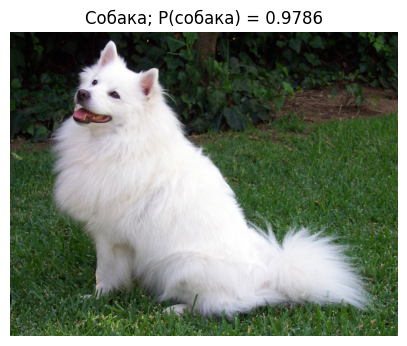

In [19]:
def show_photo(path, probability):
    with Image.open(path) as image:
        picture = ImageOps.exif_transpose(image).convert("RGB")
        plt.figure(figsize=(5, 5))
        plt.imshow(picture)
    label = "Собака" if probability >= 0.5 else "Кошка"
    plt.title(f"{label}; P(собака) = {probability:.4f}")
    plt.axis("off")
    plt.show()


PHOTO_PATH = ""
photo = Path(PHOTO_PATH).expanduser() if PHOTO_PATH else hw4.demo_photo()
photo_probability = float(predict_external([photo])[0])
show_photo(photo, photo_probability)


## Выводы

С дополнительными фотографиями ансамбль дал точность 99,04% на тестовой выборке. Это на 12 правильных ответов больше, чем у варианта на данных курса (98,56%).
